# E-commerce Sales Data Analysis
**Note:** This project uses synthetic sample data for practice, not real company data.

## 1. Upload or load the CSV
In Google Colab, upload `ecommerce_sales.csv` from the project's `data` folder when prompted.

In [1]:
from google.colab import files
uploaded = files.upload()  # Select ecommerce_sales.csv
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('ecommerce_sales.csv')
df.head()

Saving ecommerce_sales.csv to ecommerce_sales.csv


,Order_ID,Order_Date,Region,Category,Product,Quantity,Unit_Price,Revenue,Cost,Profit
0,ORD1001,2025-01-01,West,Fashion,Sneakers,3,2436.67,7310.01,5396.90,1913.11
1,ORD1002,2025-01-03,East,Books,Python Guide,4,651.49,2605.96,1523.42,1082.54
2,ORD1003,2025-01-05,South,Home,Storage Box,2,564.01,1128.02,816.51,311.51
3,ORD1004,2025-01-07,West,Home,Bedsheet,3,1219.65,3658.95,2075.47,1583.48
4,ORD1005,2025-01-09,West,Books,Business Book,4,484.84,1939.36,1252.29,687.07


## 2. Inspect and clean

In [2]:
print('Shape:', df.shape)
print(df.isna().sum())
print('Duplicate order IDs:', df['Order_ID'].duplicated().sum())
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
df['Region'] = df['Region'].fillna('Unknown')
df['Product'] = df['Product'].fillna('Unknown Product')
df = df.drop_duplicates(subset=['Order_ID'], keep='first').dropna(subset=['Order_Date', 'Revenue', 'Profit'])
print('Cleaned rows:', len(df))

Shape: (180, 10)
Order_ID      0
Order_Date    0
Region        1
Category      0
Product       1
Quantity      0
Unit_Price    0
Revenue       0
Cost          0
Profit        0
dtype: int64
Duplicate order IDs: 1
Cleaned rows: 179


## 3. Calculate KPIs

In [3]:
revenue = df['Revenue'].sum()
profit = df['Profit'].sum()
orders = df['Order_ID'].nunique()
print(f'Total revenue: ₹{revenue:,.2f}')
print(f'Total profit: ₹{profit:,.2f}')
print(f'Unique orders: {orders}')
print(f'Average revenue per order: ₹{revenue/orders:,.2f}')
print(f'Profit margin: {profit/revenue*100:.2f}%')

Total revenue: ₹578,022.35
Total profit: ₹175,802.04
Unique orders: 179
Average revenue per order: ₹3,229.18
Profit margin: 30.41%


## 4. Category and regional analysis

In [4]:
category = df.groupby('Category', as_index=False).agg(Revenue=('Revenue','sum'), Profit=('Profit','sum')).sort_values('Revenue', ascending=False)
region = df.groupby('Region', as_index=False).agg(Revenue=('Revenue','sum'), Profit=('Profit','sum')).sort_values('Revenue', ascending=False)
display(category)
display(region)

,Category,Revenue,Profit
2,Fashion,218739.62,61775.04
1,Electronics,189093.83,61112.46
3,Home,111307.69,34099.05
0,Books,58881.21,18815.49


,Region,Revenue,Profit
4,West,152707.36,46283.59
0,East,147380.63,45127.03
2,South,140764.04,42778.07
1,North,131225.12,39242.15
3,Unknown,5945.20,2371.20


## 5. Visualize revenue

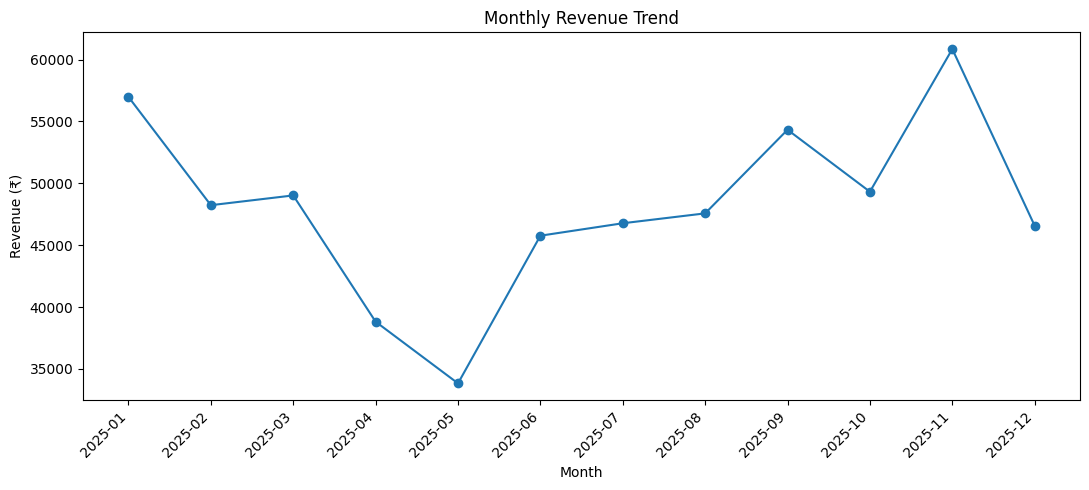

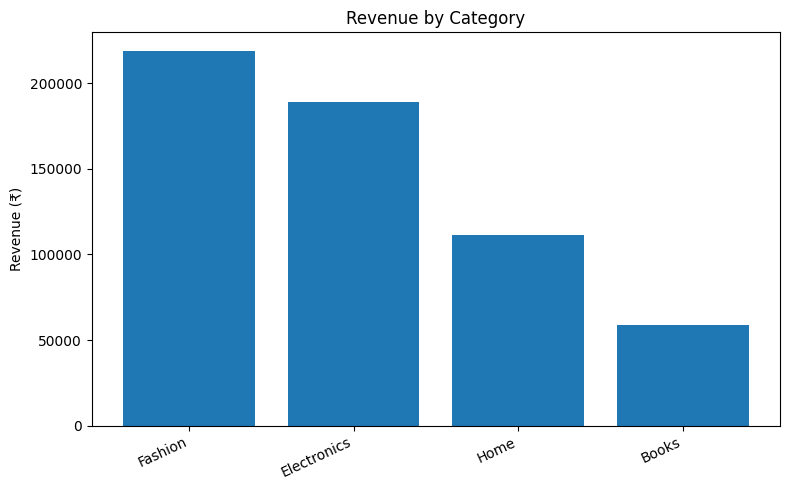

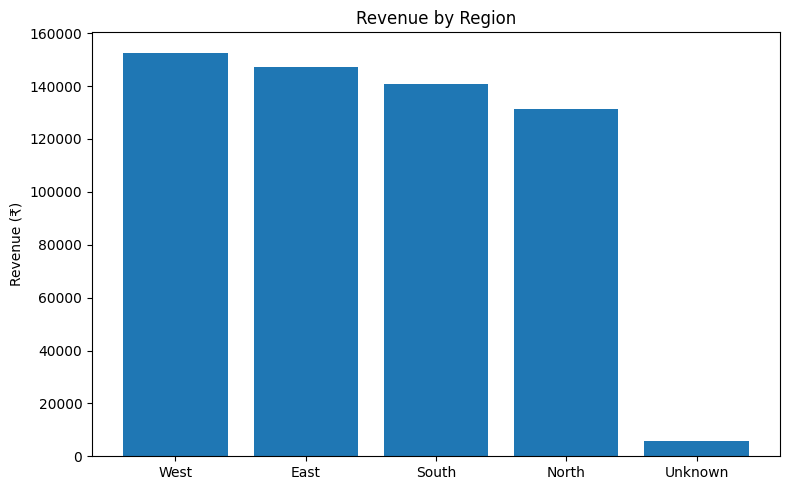

In [5]:
monthly = df.assign(Month=df['Order_Date'].dt.to_period('M').astype(str)).groupby('Month', as_index=False)['Revenue'].sum()
plt.figure(figsize=(11,5))
plt.plot(monthly['Month'], monthly['Revenue'], marker='o')
plt.title('Monthly Revenue Trend')
plt.xlabel('Month'); plt.ylabel('Revenue (₹)'); plt.xticks(rotation=45, ha='right'); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
plt.bar(category['Category'], category['Revenue'])
plt.title('Revenue by Category'); plt.ylabel('Revenue (₹)'); plt.xticks(rotation=25, ha='right'); plt.tight_layout(); plt.show()

plt.figure(figsize=(8,5))
plt.bar(region['Region'], region['Revenue'])
plt.title('Revenue by Region'); plt.ylabel('Revenue (₹)'); plt.tight_layout(); plt.show()

## 6. Explain your insights
Use the output to identify the highest-revenue category, region, and month. Explain what you observe and suggest actions. Do not claim the synthetic dataset represents a real company.